In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy.fft import fft, fftfreq
from scipy import signal
from os import listdir
from os.path import isfile, join
import re
import MasterPSD as PSD
from multiprocessing import Pool, cpu_count
from tqdm import tqdm
import VisAnalysis as Vis

In [2]:
NNF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Night2LongNoFibre", verbose=True)
NF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Night2Long", verbose=True)
MNF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Medium2LongNoFibre", verbose=True)
MF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Medium2Long", verbose=True)
DF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Day2Long", verbose=True)
DNF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Day2LongNoFibre", verbose=True)

Loaded 14 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Night2LongNoFibre
Loaded 12 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Night2Long
Loaded 12 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Medium2LongNoFibre
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Medium2Long
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Day2Long
Loaded 12 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Day2LongNoFibre


In [4]:
NL = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-28", subfolder="Night2Long", verbose=True)
NLF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-28", subfolder="Night2LongFast", verbose=True)
NLVF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-28", subfolder="Night2LongVeryFast", verbose=True)

Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-28\Night2Long
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-28\Night2LongFast
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-28\Night2LongVeryFast


In [5]:
for i in range(len(DNF)):
    print(i,DNF[i]['name'])

0 Day_2_1MhzGate_107uWperArm_Rmp1000Hz_voaramp
1 Day_2_1MhzGate_107uWperArm_Rmp100Hz_voaramp
2 Day_2_1MhzGate_107uWperArm_Rmp10Hz_voaramp
3 Day_2_1MhzGate_107uWperArm_Rmp1Hz_voaramp
4 Day_2_1MhzGate_107uWperArm_Rmp1000Hz_nomodulation
5 Day_2_1MhzGate_107uWperArm_Rmp100Hz_nomodulation
6 Day_2_1MhzGate_107uWperArm_Rmp10Hz_nomodulation
7 Day_2_1MhzGate_107uWperArm_Rmp1Hz_nomodulation
8 Day_2_1MhzGate_107uWperArm_Rmp1000Hz
9 Day_2_1MhzGate_107uWperArm_Rmp100Hz
10 Day_2_1MhzGate_107uWperArm_Rmp10Hz
11 Day_2_1MhzGate_107uWperArm_Rmp1Hz


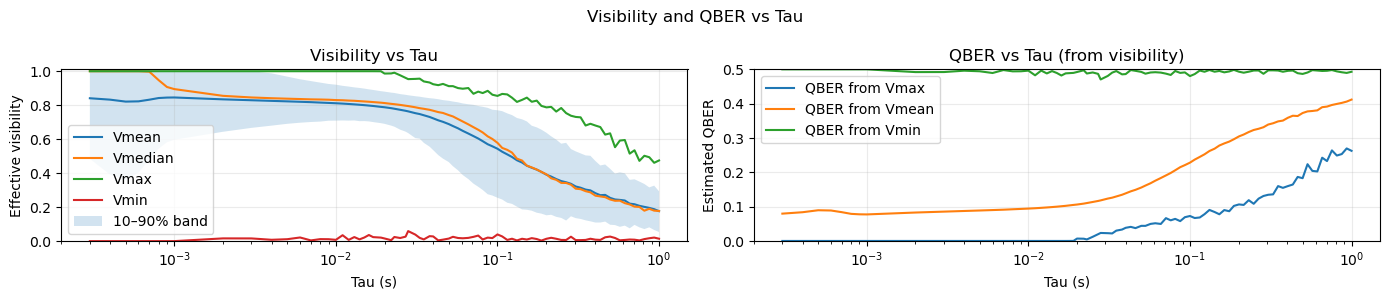

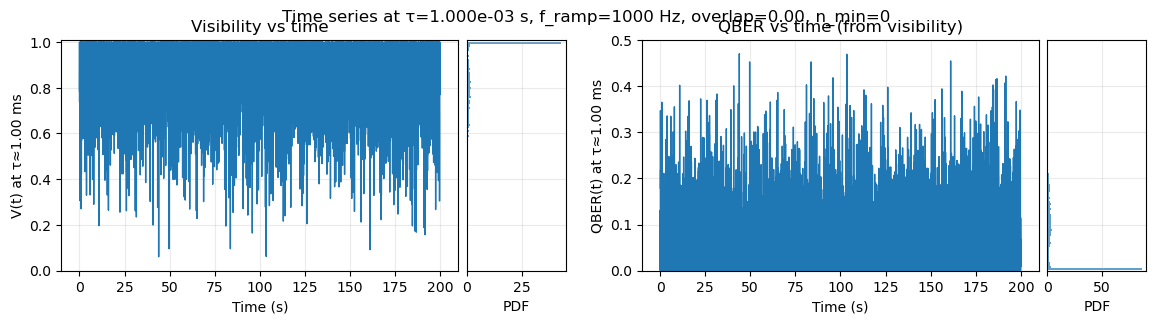

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 10, 'S_samples': 10, 'tau_eff_s': 0.001, 'step_eff_s': 0.001, 'n_windows_total': 200000, 'n_windows_used': 200000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.8929986312762556
V mean:   0.8442087660997245
V 10–90%: 0.5955431860265521 … 0.999


In [19]:
DNF_1000_em2=Vis.AnalyseMeasurement_NewNumba(DNF,8,100,1000,1e-4,1,0.001,10,overlap=0,hist_bins=100)

In [20]:
np.save('DNF_1000_em_Numa.npy',DNF_1000_em2[1])

In [64]:
DNF_1000_em=Vis.AnalyseMeasurement_New(DNF,8,100,1000,1e-4,1,0.01,10,overlap=0,hist_bins=100)

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 100, 'S': 100, 'tau': 0.01, 'step': 0.01, 'n_windows_total': 20000, 'n_windows_used': 20000, 'mean_counts_per_window_used': 221.98195}
V median: 0.7456572307289019
V mean:   0.7318611022720866
V 10–90%: 0.646839584921762 … 0.8249271439932367


In [63]:
DNF_1000_nm2=Vis.AnalyseMeasurement_NewNumba(DNF,4,100,1000,1e-4,1,0.01,10,overlap=0,hist_bins=100)

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 100, 'S_samples': 100, 'tau_eff_s': 0.01, 'step_eff_s': 0.01, 'n_windows_total': 20000, 'n_windows_used': 20000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.8796658369353847
V mean:   0.8795886835545722
V 10–90%: 0.8046316946004811 … 0.9563912592096373


In [29]:
DNF_1000_nm2[0][0]

[array([5.000000e-04, 1.500000e-03, 2.500000e-03, ..., 1.999975e+02,
        1.999985e+02, 1.999995e+02]),
 array([0.999     , 0.999     , 0.99101042, ..., 0.84629754, 0.999     ,
        0.999     ]),
 {'dt': 0.0001,
  'K_samples': 10,
  'S_samples': 10,
  'tau_eff_s': 0.001,
  'step_eff_s': 0.001,
  'n_windows_total': 200000,
  'n_windows_used': 200000,
  'n_phase': 64,
  'iters_ab': 8,
  'lam_floor': 1e-06,
  'n_min_counts': 0.0,
  'clip_for_qber': False}]

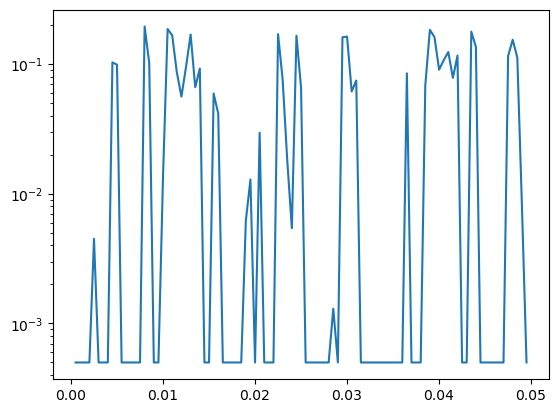

In [7]:
plt.semilogy(tcent[0:99],QBERir[0:99])

In [69]:
tcent2, Vt2, QBERir2, diag2 = Vis.lockin_visibility_vs_time_mle_numba(
        NNF[4]['data']['timestamps'], NNF[4]['data']['counts'], f_ramp=1000, tau=0.003, step=None,
        n_min=0, clip=False,make_plots = False, verbose=False, n_phase = 128,iters_ab = 8,
    lam_floor = 1e-9)

In [61]:
import numpy as np
import matplotlib.pyplot as plt

def estimate_visibility_sigma_vs_tau(
    sample_rate_hz: float,
    mean_counts_per_sample: float,
    taus: np.ndarray,
):
    """
    Rough visibility uncertainty vs tau from photon statistics.

    Parameters
    ----------
    sample_rate_hz : float
        Detector sampling rate, e.g. 10_000 for 10 kHz.
    mean_counts_per_sample : float
        Mean counts per sample/bin (your ~3).
    taus : array_like
        Tau values in seconds.

    Returns
    -------
    N_tau : np.ndarray
        Expected counts per tau-window.
    sigma_conservative : np.ndarray
        ~ 1/sqrt(N_tau)
    sigma_fringe_like : np.ndarray
        ~ sqrt(2/N_tau)
    rate_cps : float
        Mean count rate in counts/s.
    """
    taus = np.asarray(taus, dtype=float)
    dt = 1.0 / float(sample_rate_hz)
    rate_cps = float(mean_counts_per_sample) / dt  # counts per second
    N_tau = rate_cps * taus

    # Avoid divide-by-zero
    N_safe = np.maximum(N_tau, 1e-12)

    sigma_conservative = 1.0 / np.sqrt(N_safe)
    sigma_fringe_like  = np.sqrt(2.0 / N_safe)

    return N_tau, sigma_conservative, sigma_fringe_like, rate_cps


def plot_sigma_vs_tau(
    sample_rate_hz: float = 10_000.0,
    mean_counts_per_sample: float = 3.0,
    tau_min: float = 1e-4,
    tau_max: float = 1.0,
    n_points: int = 300,
    mark_tau: float = 1e-3,  # your tau=1 ms
):
    taus = np.logspace(np.log10(tau_min), np.log10(tau_max), n_points)

    N_tau, sig1, sig2, rate_cps = estimate_visibility_sigma_vs_tau(
        sample_rate_hz, mean_counts_per_sample, taus
    )

    # Print a quick readout at mark_tau
    N_mark, s1_mark, s2_mark, _ = estimate_visibility_sigma_vs_tau(
        sample_rate_hz, mean_counts_per_sample, np.array([mark_tau])
    )
    print(f"[Inputs] sample_rate = {sample_rate_hz:g} Hz, mean counts/sample = {mean_counts_per_sample:g}")
    print(f"[Rate]   ~ {rate_cps:,.0f} counts/s")
    print(f"[At tau={mark_tau:g} s] expected counts/window N_tau ~ {N_mark[0]:.1f}")
    print(f"  sigma_V (1/sqrt(N))        ~ {s1_mark[0]:.3f}")
    print(f"  sigma_V (sqrt(2)/sqrt(N))  ~ {s2_mark[0]:.3f}")

    # Plot sigma vs tau
    plt.figure(figsize=(9, 4))
    plt.plot(taus, sig1, label=r"$\sigma_V \approx 1/\sqrt{N_\tau}$ (conservative)")
    plt.plot(taus, sig2, label=r"$\sigma_V \approx \sqrt{2/N_\tau}$ (fringe-like)")

    # Mark your tau
    plt.axvline(mark_tau, linestyle="--", linewidth=1, label=f"tau = {mark_tau:g} s")

    # Reference bands for “what you can resolve”
    for target in [1e-1, 1e-2, 1e-3, 1e-4]:
        plt.axhline(target, linestyle=":", linewidth=1)

    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Tau (s)")
    plt.ylabel("Estimated visibility uncertainty (order-of-magnitude)")
    plt.title("Photon-statistics-limited visibility uncertainty vs integration time")
    plt.grid(True, which="both", alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Optional: plot expected counts per window
    plt.figure(figsize=(9, 4))
    plt.plot(taus, N_tau, label=r"$N_\tau \approx \mathrm{rate}\cdot \tau$")
    plt.axvline(mark_tau, linestyle="--", linewidth=1, label=f"tau = {mark_tau:g} s")
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Tau (s)")
    plt.ylabel("Expected counts per window")
    plt.title("Expected counts per tau-window")
    plt.grid(True, which="both", alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()


# --- run with your values ---
if __name__ == "__main__":
    plot_sigma_vs_tau(
        sample_rate_hz=10_000.0,
        mean_counts_per_sample=2.199422,
        tau_min=1e-4,
        tau_max=1.0,
        n_points=300,
        mark_tau=1e-3,  # 1 ms
    )


[Inputs] sample_rate = 10000 Hz, mean counts/sample = 2.19942
[Rate]   ~ 21,994 counts/s
[At tau=0.001 s] expected counts/window N_tau ~ 22.0
  sigma_V (1/sqrt(N))        ~ 0.213
  sigma_V (sqrt(2)/sqrt(N))  ~ 0.302


In [59]:
np.mean(DNF[4]['data']['counts'])

2.199422

In [57]:
plt.semilogy(tcent[0:99],QBERir[0:99])

In [51]:
%matplotlib qt
plt.semilogy(tcent[0:299],Vt[0:299])
plt.semilogy(tcent2[0:299],Vt2[0:299])

In [22]:
np.save('DNF_1000_nm_Numa.npy',DNF_1000_nm2[1])

In [67]:
DNF_1000_nm=Vis.AnalyseMeasurement_New(DNF,4,100,1000,1e-4,1,0.01,10,overlap=0,hist_bins=100)

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 100, 'S': 100, 'tau': 0.01, 'step': 0.01, 'n_windows_total': 20000, 'n_windows_used': 20000, 'mean_counts_per_window_used': 219.9422}
V median: 0.7826746291783029
V mean:   0.7826336855919511
V 10–90%: 0.7154031772173362 … 0.8491371232026446


In [15]:
for i in range(len(DF)):
    print(i,DF[i]['name'])

0 Day_2_1MhzGate_85uWperArm_Rmp1Hz
1 Day_2_1MhzGate_85uWperArm_Rmp1000Hz_voaramp
2 Day_2_1MhzGate_85uWperArm_Rmp100Hz_voaramp
3 Day_2_1MhzGate_85uWperArm_Rmp10Hz_voaramp
4 Day_2_1MhzGate_85uWperArm_Rmp1Hz_voaramp
5 Day_2_1MhzGate_85uWperArm_Rmp1000Hz_nomodulation
6 Day_2_1MhzGate_85uWperArm_Rmp100Hz_nomodulation
7 Day_2_1MhzGate_85uWperArm_Rmp10Hz_nomodulation
8 Day_2_1MhzGate_85uWperArm_Rmp1Hz_nomodulation
9 Day_2_1MhzGate_85uWperArm_Rmp1000Hz
10 Day_2_1MhzGate_85uWperArm_Rmp100Hz
11 Day_2_1MhzGate_85uWperArm_Rmp10Hz
12 Day_2_1MhzGate_85uWperArm_Rmp1Hz


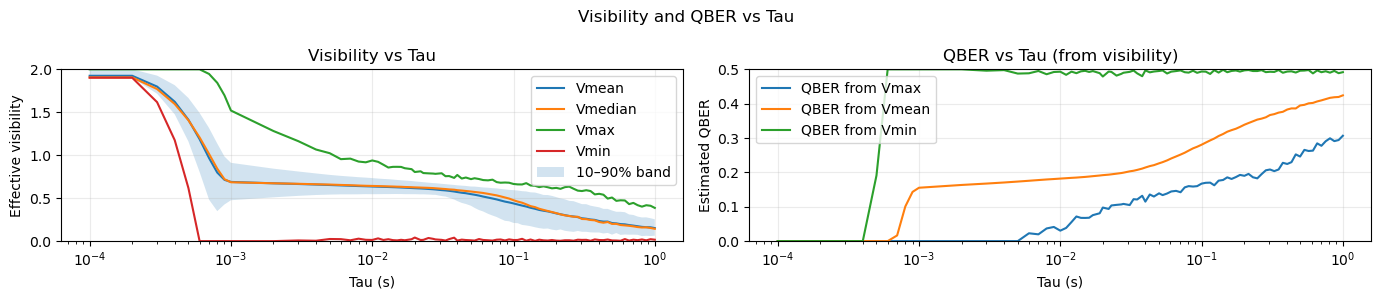

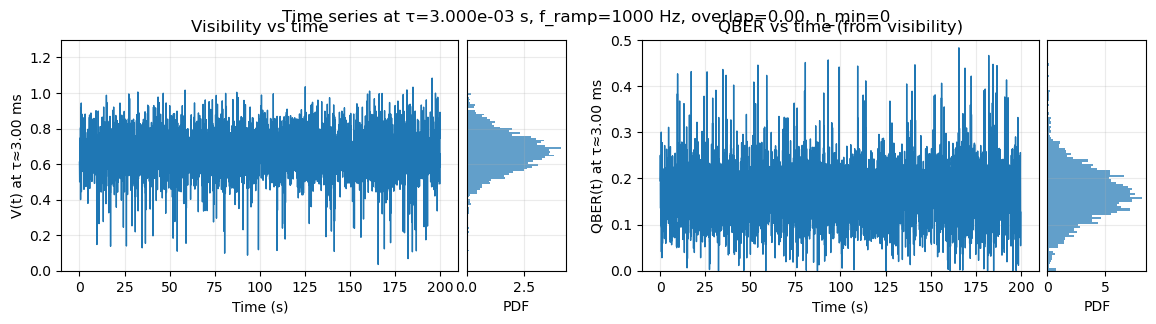

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 30, 'S': 30, 'tau': 0.003, 'step': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'mean_counts_per_window_used': 81.96107461074611}
V median: 0.667345341243184
V mean:   0.6649773966204904
V 10–90%: 0.5270884625297636 … 0.8103339521300208


In [21]:
DF_1000_em=Vis.AnalyseMeasurement_New(DF,9,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

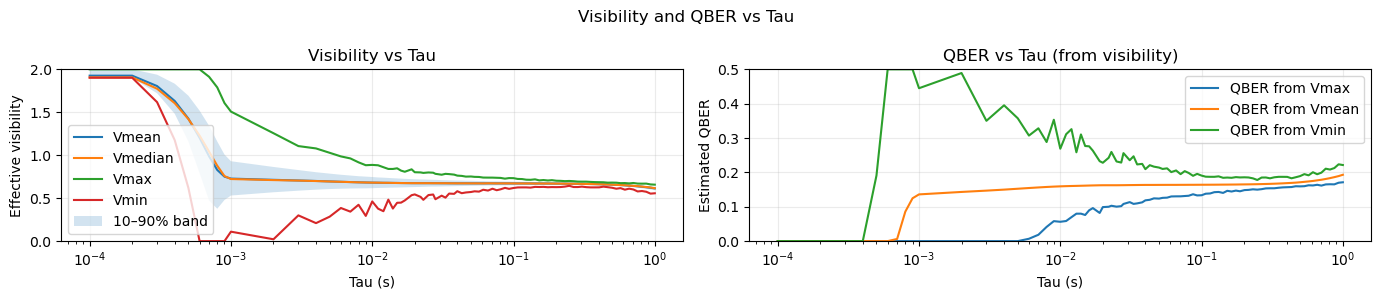

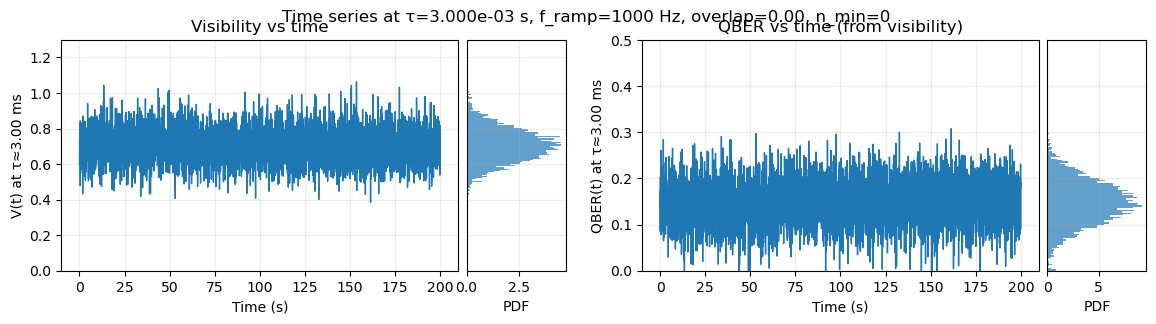

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 30, 'S': 30, 'tau': 0.003, 'step': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'mean_counts_per_window_used': 81.70977709777098}
V median: 0.7046931796844351
V mean:   0.7060695690653079
V 10–90%: 0.5872672573940396 … 0.8272919294625918


In [23]:
DF_1000_nm=Vis.AnalyseMeasurement_New(DF,5,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [19]:
for i in range(len(MNF)):
    print(i,MNF[i]['name'])

0 Medium_2_1MhzGate_167uWperArm_Rmp1000Hz_voaramp
1 Medium_2_1MhzGate_167uWperArm_Rmp100Hz_voaramp
2 Medium_2_1MhzGate_167uWperArm_Rmp10Hz_voaramp
3 Medium_2_1MhzGate_167uWperArm_Rmp1Hz_voaramp
4 Medium_2_1MhzGate_167uWperArm_Rmp1000Hz_nomodulation
5 Medium_2_1MhzGate_167uWperArm_Rmp100Hz_nomodulation
6 Medium_2_1MhzGate_167uWperArm_Rmp10Hz_nomodulation
7 Medium_2_1MhzGate_167uWperArm_Rmp1Hz_nomodulation
8 Medium_2_1MhzGate_167uWperArm_Rmp1000Hz
9 Medium_2_1MhzGate_167uWperArm_Rmp100Hz
10 Medium_2_1MhzGate_167uWperArm_Rmp10Hz
11 Medium_2_1MhzGate_167uWperArm_Rmp1Hz


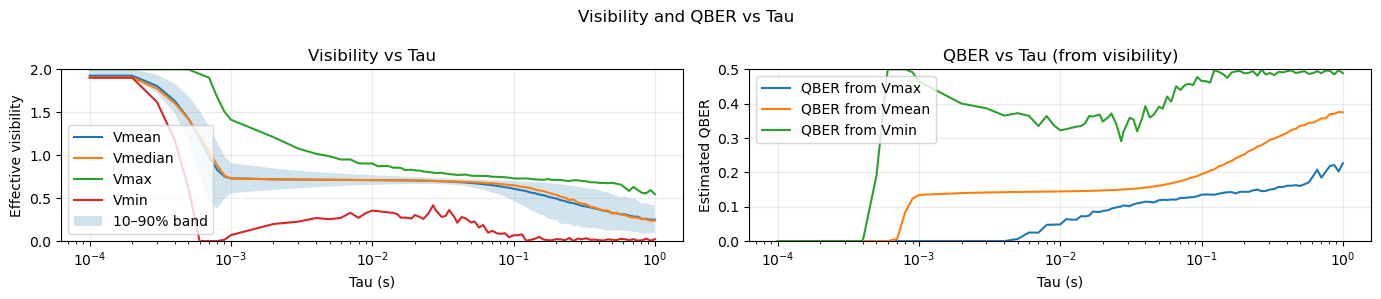

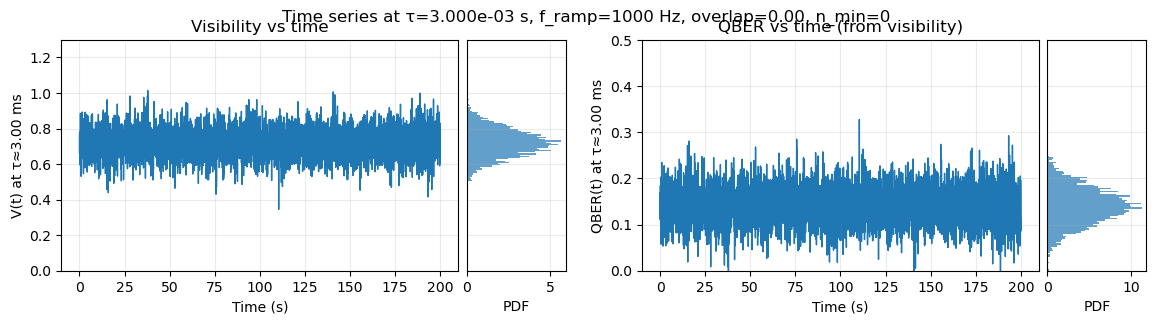

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 30, 'S': 30, 'tau': 0.003, 'step': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'mean_counts_per_window_used': 83.06718567185672}
V median: 0.7166938344976936
V mean:   0.7168100734440427
V 10–90%: 0.6144218701471538 … 0.8195321961449634


In [24]:
MNF_1000_em=Vis.AnalyseMeasurement_New(MNF,8,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

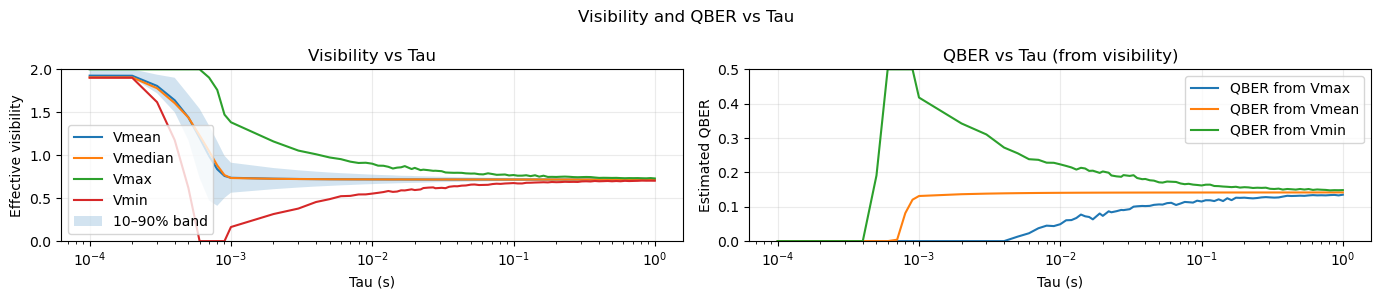

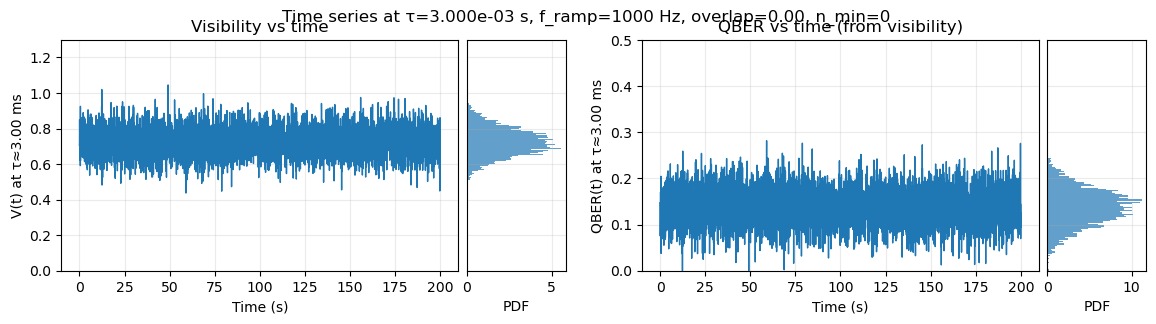

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 30, 'S': 30, 'tau': 0.003, 'step': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'mean_counts_per_window_used': 82.91889418894189}
V median: 0.7228180879785435
V mean:   0.7235597291894393
V 10–90%: 0.6236384181391661 … 0.8245412745069045


In [26]:
MNF_1000_nm=Vis.AnalyseMeasurement_New(MNF,4,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [22]:
for i in range(len(MF)):
    print(i,MF[i]['name'])

0 Medium_2_1MhzGate_130uWperArm_Rmp1000Hz_voaramp
1 Medium_2_1MhzGate_130uWperArm_Rmp100Hz_voaramp
2 Medium_2_1MhzGate_130uWperArm_Rmp10Hz_voaramp
3 Medium_2_1MhzGate_130uWperArm_Rmp1Hz_voaramp
4 Medium_2_1MhzGate_130uWperArm_Rmp1000Hz_nomodulation
5 Medium_2_1MhzGate_130uWperArm_Rmp100Hz_nomodulation
6 Medium_2_1MhzGate_130uWperArm_Rmp10Hz_nomodulation
7 Medium_2_1MhzGate_130uWperArm_Rmp1Hz_nomodulation
8 Medium_2_1MhzGate_130uWperArm_Rmp1000Hz
9 Medium_2_1MhzGate_130uWperArm_Rmp100Hz
10 Medium_2_1MhzGate_130uWperArm_Rmp10Hz
11 Medium_2_1MhzGate_130uWperArm_Rmp1Hz
12 Medium_2_1MhzGate_167uWperArm_Rmp1000Hz_voaramp


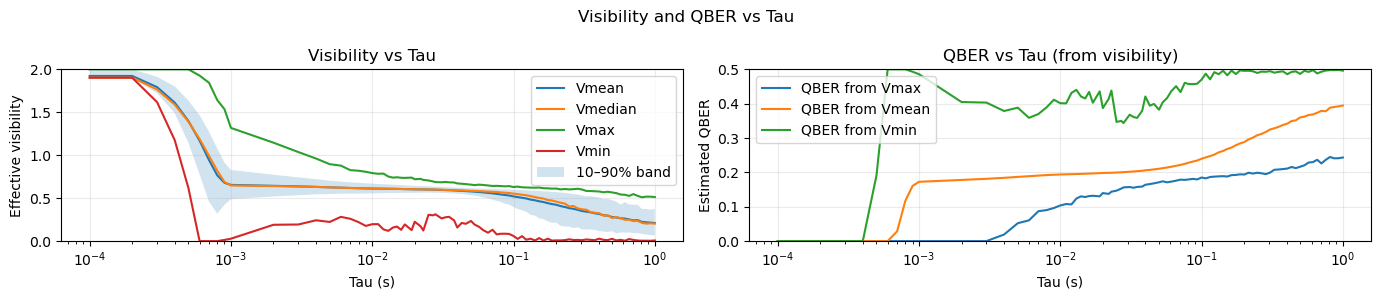

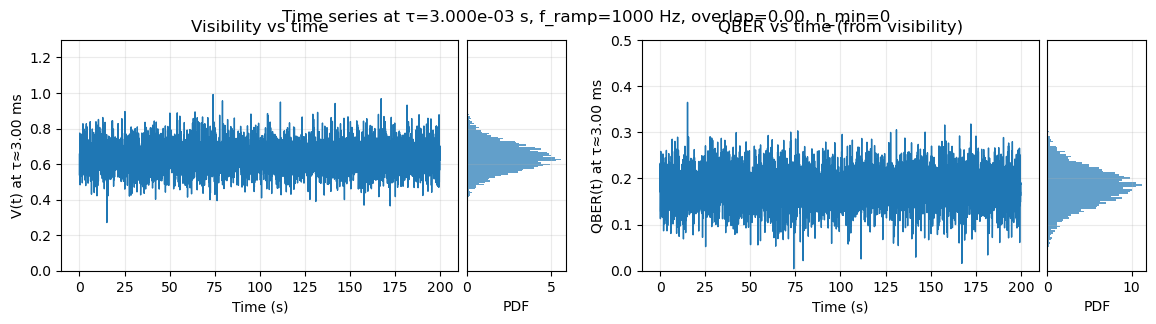

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 30, 'S': 30, 'tau': 0.003, 'step': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'mean_counts_per_window_used': 99.10584105841059}
V median: 0.6356153629672925
V mean:   0.6372556648075756
V 10–90%: 0.5338927277868658 … 0.7427172848088903


In [29]:
MF_1000_em=Vis.AnalyseMeasurement_New(MF,8,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

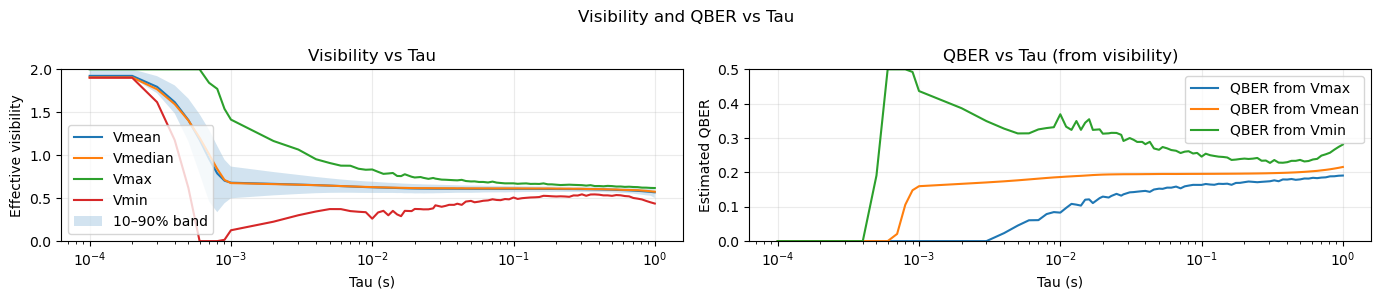

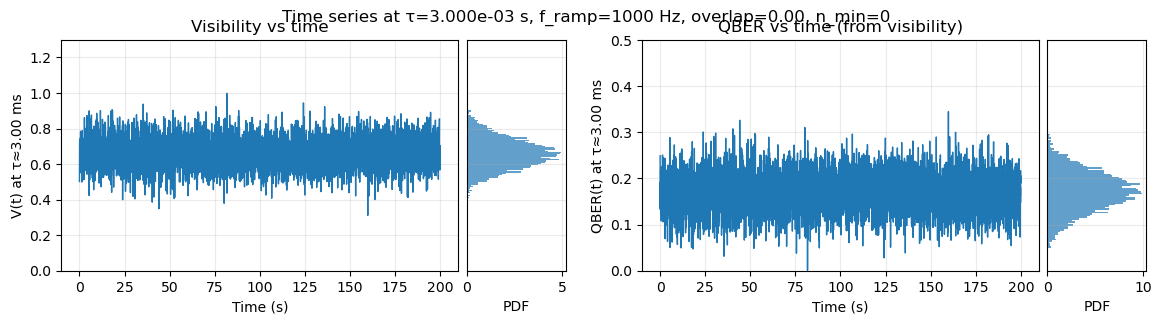

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 30, 'S': 30, 'tau': 0.003, 'step': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'mean_counts_per_window_used': 91.14589145891459}
V median: 0.6566049913055045
V mean:   0.6583913642390974
V 10–90%: 0.5484604215036185 … 0.7706741031008065


In [30]:
MF_1000_nm=Vis.AnalyseMeasurement_New(MF,4,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [25]:
for i in range(len(NNF)):
    print(i,NNF[i]['name'])

0 Night_2_1MhzGate_195uWperArm_Rmp1000Hz_voaramp
1 Night_2_1MhzGate_195uWperArm_Rmp100Hz_voaramp
2 Night_2_1MhzGate_195uWperArm_Rmp10Hz_voaramp
3 Night_2_1MhzGate_195uWperArm_Rmp1Hz_voaramp
4 Night_2_1MhzGate_195uWperArm_Rmp1000Hz_nomodulation
5 Night_2_1MhzGate_195uWperArm_Rmp100Hz_nomodulation
6 Night_2_1MhzGate_195uWperArm_Rmp10Hz_nomodulation
7 Night_2_1MhzGate_195uWperArm_Rmp1Hz_nomodulation
8 Night_2_1MhzGate_195uWperArm_Rmp1000Hz
9 Night_2_1MhzGate_195uWperArm_Rmp100Hz
10 Night_2_1MhzGate_195uWperArm_Rmp10Hz
11 Night_2_1MhzGate_195uWperArm_Rmp1Hz
12 Test_Night_2_1MhzGate_195uWperArm_Rmp1Hz_nomodulation
13 Test_Night_2_1MhzGate_195uWperArm_Rmp1Hz_nomodulation


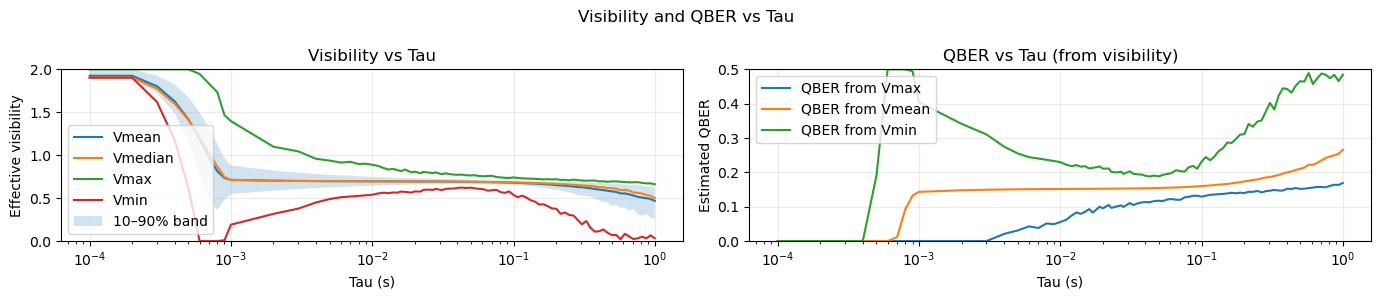

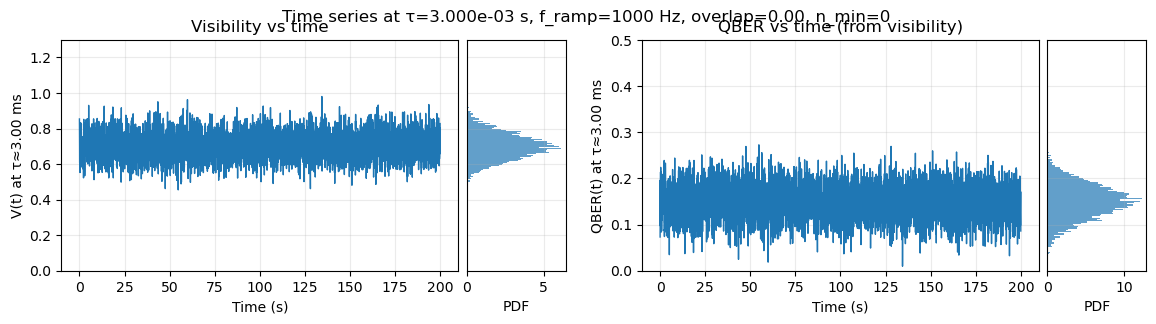

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 30, 'S': 30, 'tau': 0.003, 'step': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'mean_counts_per_window_used': 88.03835538355384}
V median: 0.7000533289514461
V mean:   0.7009006024025336
V 10–90%: 0.6063431384498903 … 0.7967895710340088


In [32]:
NNF_1000_em=Vis.AnalyseMeasurement_New(NNF,8,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

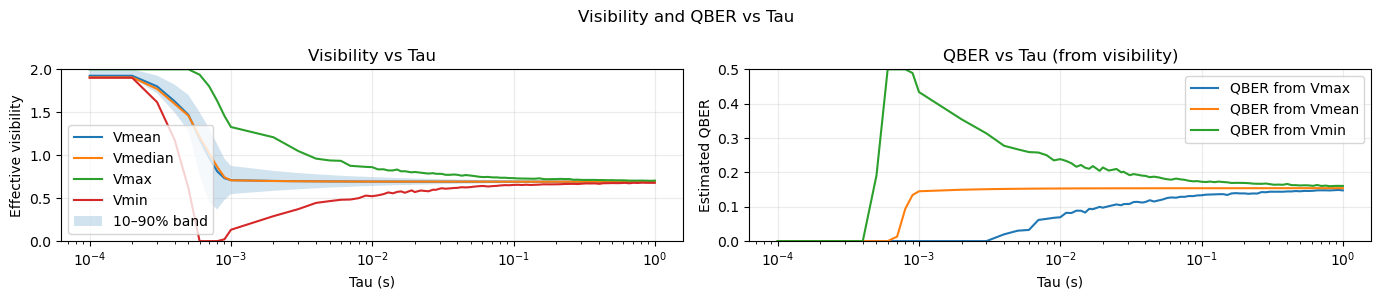

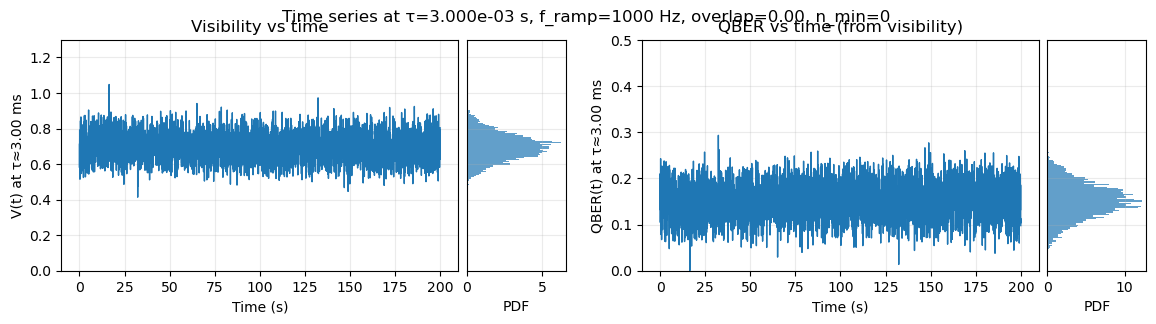

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 30, 'S': 30, 'tau': 0.003, 'step': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'mean_counts_per_window_used': 88.739987399874}
V median: 0.6968825266060892
V mean:   0.6977120953052948
V 10–90%: 0.6035218210070588 … 0.7924453062014444


In [33]:
NNF_1000_nm=Vis.AnalyseMeasurement_New(NNF,4,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [29]:
for i in range(len(NF)):
    print(i,NF[i]['name'])

0 Night_2_1MhzGate_153uWperArm_Rmp1000Hz_voaramp
1 Night_2_1MhzGate_153uWperArm_Rmp100Hz_voaramp
2 Night_2_1MhzGate_153uWperArm_Rmp10Hz_voaramp
3 Night_2_1MhzGate_153uWperArm_Rmp1Hz_voaramp
4 Night_2_1MhzGate_153uWperArm_Rmp1000Hz_nomodulation
5 Night_2_1MhzGate_153uWperArm_Rmp100Hz_nomodulation
6 Night_2_1MhzGate_153uWperArm_Rmp10Hz_nomodulation
7 Night_2_1MhzGate_153uWperArm_Rmp1Hz_nomodulation
8 Night_2_1MhzGate_153uWperArm_Rmp1000Hz
9 Night_2_1MhzGate_153uWperArm_Rmp100Hz
10 Night_2_1MhzGate_153uWperArm_Rmp10Hz
11 Night_2_1MhzGate_153uWperArm_Rmp1Hz


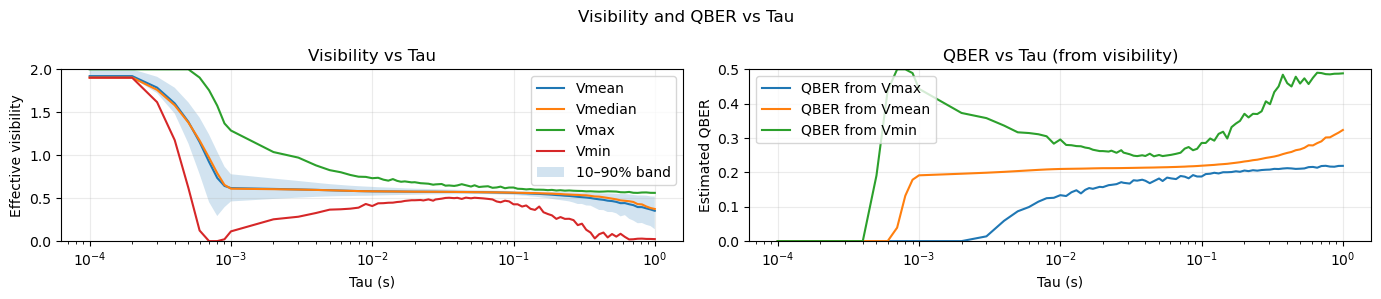

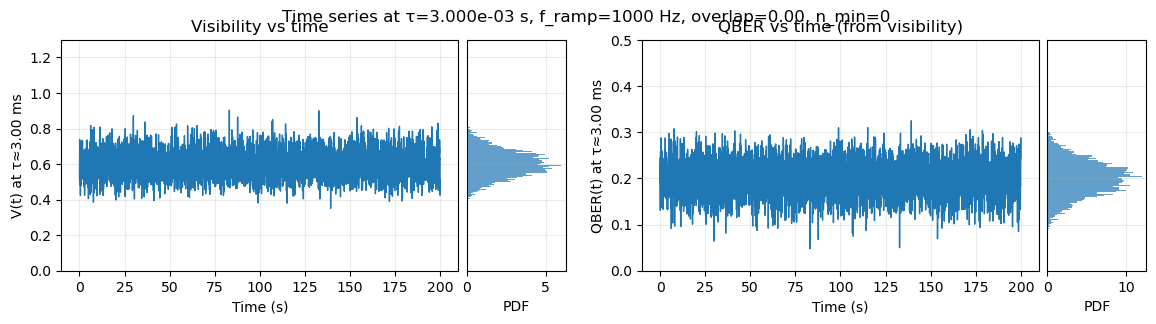

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 30, 'S': 30, 'tau': 0.003, 'step': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'mean_counts_per_window_used': 106.54422044220442}
V median: 0.6001314198941073
V mean:   0.601825838991632
V 10–90%: 0.506074704477771 … 0.7000470516548218


In [35]:
NF_1000_em=Vis.AnalyseMeasurement_New(NF,8,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

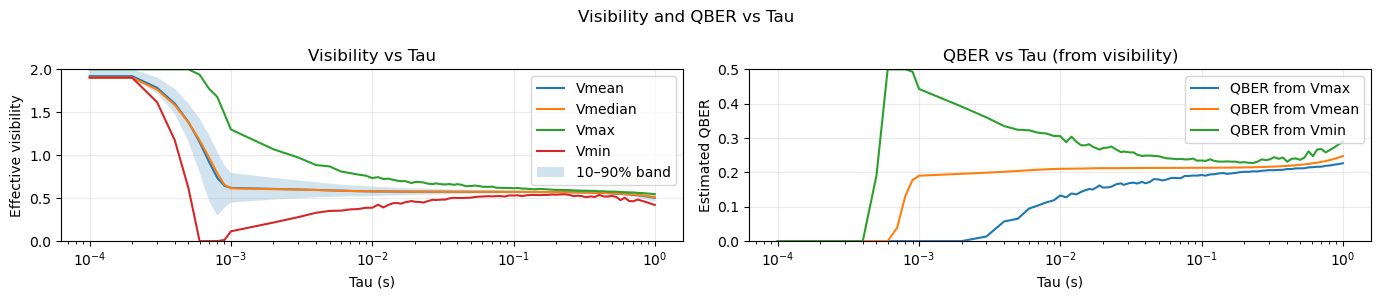

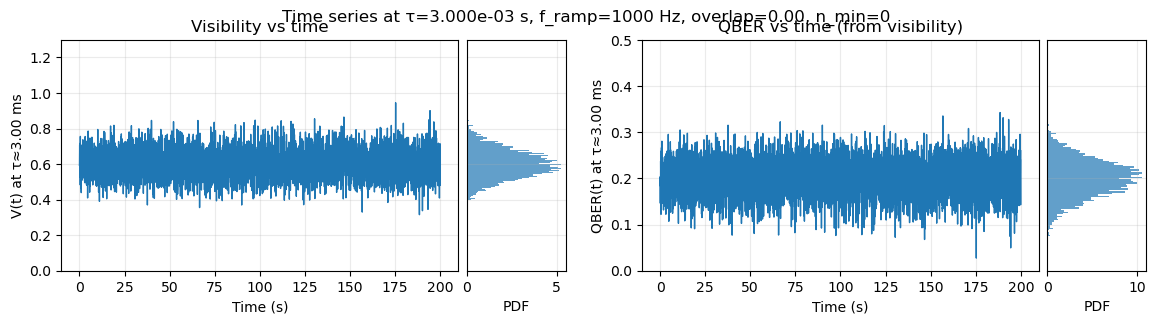

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 30, 'S': 30, 'tau': 0.003, 'step': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'mean_counts_per_window_used': 98.419974199742}
V median: 0.5995535627624226
V mean:   0.6015332846279076
V 10–90%: 0.4989344381813814 … 0.7063953300333059


In [36]:
NF_1000_nm=Vis.AnalyseMeasurement_New(NF,4,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [25]:
NF_1000_nm[0][2]

[array([5.000000e-04, 4.050000e-02, 8.050000e-02, ..., 1.998805e+02,
        1.999205e+02, 1.999605e+02]),
 array([0.15583458, 0.1454452 , 0.23219397, ..., 0.19304085, 0.11011483,
        0.05970776])]

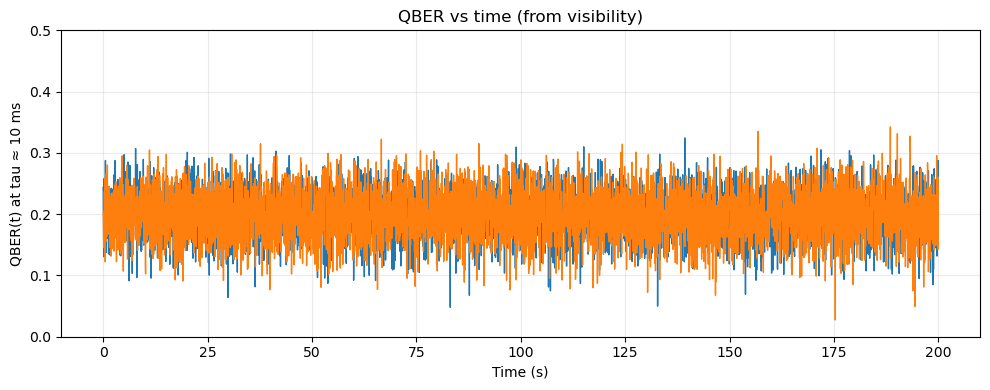

In [41]:
plt.figure(figsize=(10, 4))
plt.plot(NF_1000_em[0][2][0], NF_1000_em[0][2][1], linewidth=1)
plt.plot(NF_1000_nm[0][2][0], NF_1000_nm[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 10 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

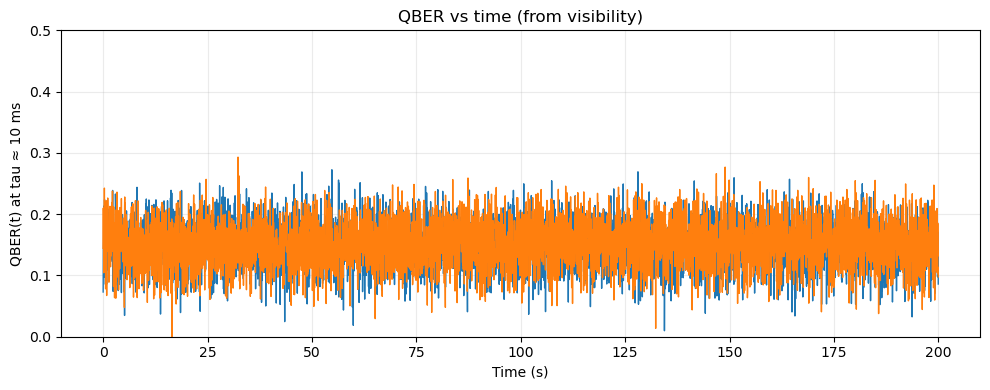

In [43]:
plt.figure(figsize=(10, 4))
plt.plot(NNF_1000_em[0][2][0], NNF_1000_em[0][2][1], linewidth=1)
plt.plot(NNF_1000_nm[0][2][0], NNF_1000_nm[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 10 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

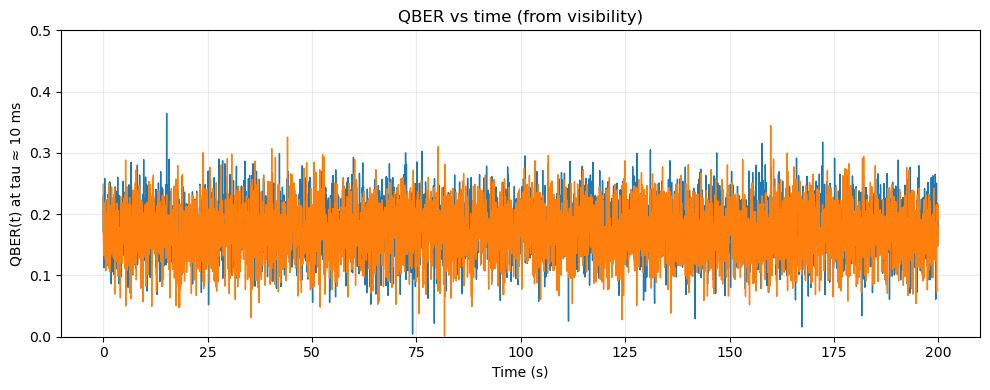

In [45]:
plt.figure(figsize=(10, 4))
plt.plot(MF_1000_em[0][2][0], MF_1000_em[0][2][1], linewidth=1)
plt.plot(MF_1000_nm[0][2][0], MF_1000_nm[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 10 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

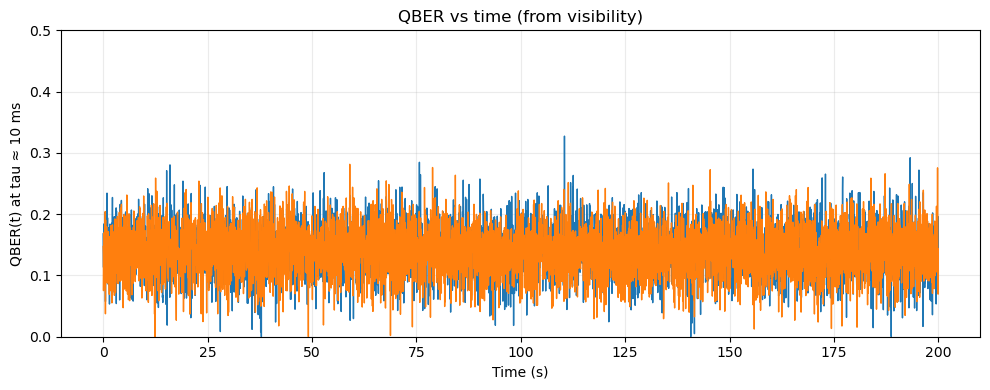

In [47]:
plt.figure(figsize=(10, 4))
plt.plot(MNF_1000_em[0][2][0], MNF_1000_em[0][2][1], linewidth=1)
plt.plot(MNF_1000_nm[0][2][0], MNF_1000_nm[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 10 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

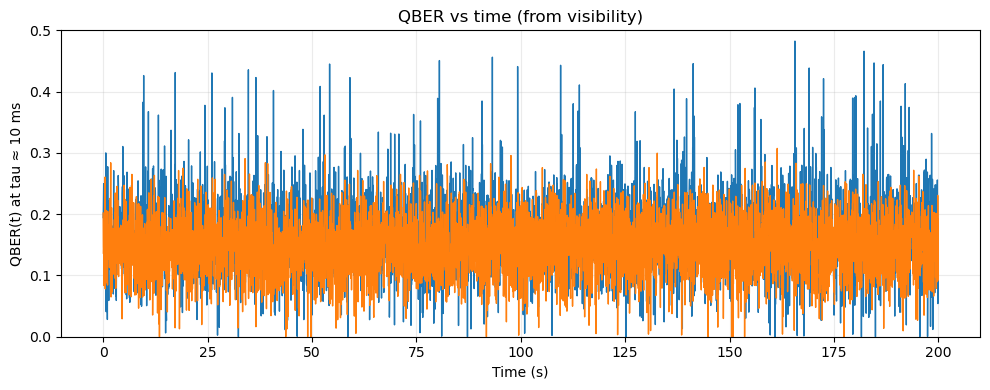

In [49]:
plt.figure(figsize=(10, 4))
plt.plot(DF_1000_em[0][2][0], DF_1000_em[0][2][1], linewidth=1)
plt.plot(DF_1000_nm[0][2][0], DF_1000_nm[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 10 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

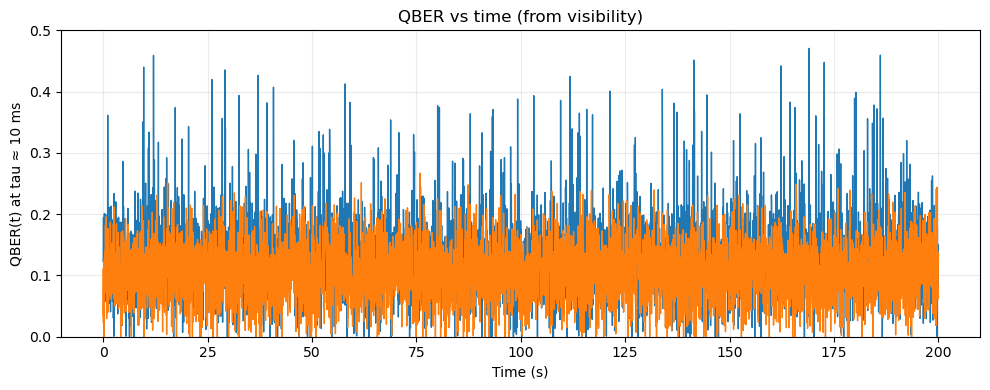

In [51]:
plt.figure(figsize=(10, 4))
plt.plot(DNF_1000_em[0][2][0], DNF_1000_em[0][2][1], linewidth=1)
plt.plot(DNF_1000_nm[0][2][0], DNF_1000_nm[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 10 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

In [111]:
for i in range(len(NL)):
    print(i,NL[i]['name'])

0 Night_2_1MhzGate_158uWperArm_Rmp1000Hz_voaramp
1 Night_2_1MhzGate_158uWperArm_Rmp100Hz_voaramp
2 Night_2_1MhzGate_158uWperArm_Rmp10Hz_voaramp
3 Night_2_1MhzGate_158uWperArm_Rmp1Hz_voaramp
4 Night_2_1MhzGate_158uWperArm_Rmp1000Hz_nomodulation
5 Night_2_1MhzGate_158uWperArm_Rmp100Hz_nomodulation
6 Night_2_1MhzGate_158uWperArm_Rmp10Hz_nomodulation
7 Night_2_1MhzGate_158uWperArm_Rmp1Hz_nomodulation
8 Night_2_1MhzGate_158uWperArm_Rmp1000Hz
9 Night_2_1MhzGate_158uWperArm_Rmp100Hz
10 Night_2_1MhzGate_158uWperArm_Rmp10Hz
11 Night_2_1MhzGate_158uWperArm_Rmp1Hz
12 Night_2_1MhzGate_158uWperArm_Rmp1Hz


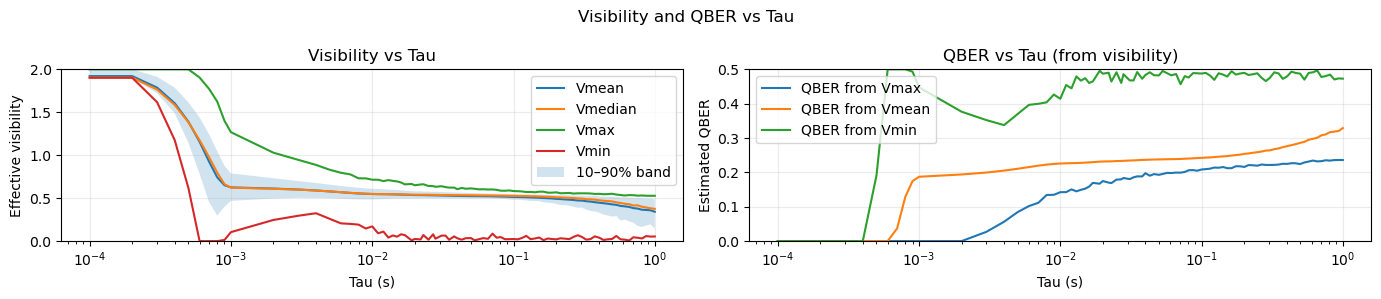

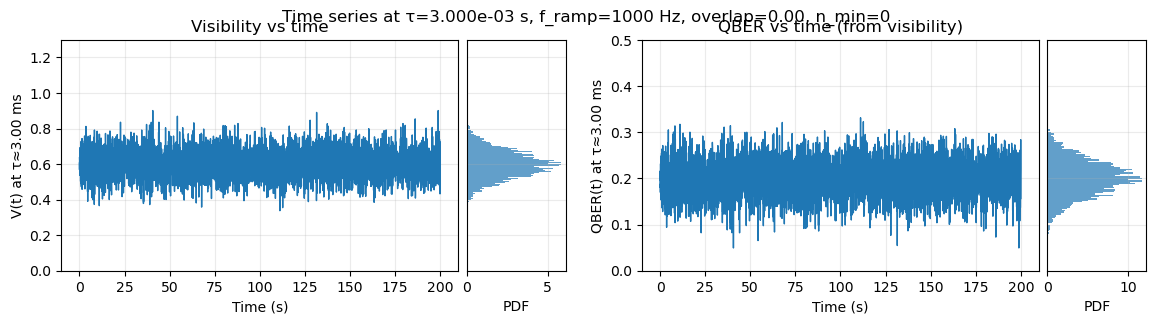

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 30, 'S': 30, 'tau': 0.003, 'step': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'mean_counts_per_window_used': 103.7149071490715}
V median: 0.5992084173738739
V mean:   0.6007760047770846
V 10–90%: 0.5041532234781269 … 0.7000099874888157


In [63]:
NL_1000_em=Vis.AnalyseMeasurement_New(NL,8,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

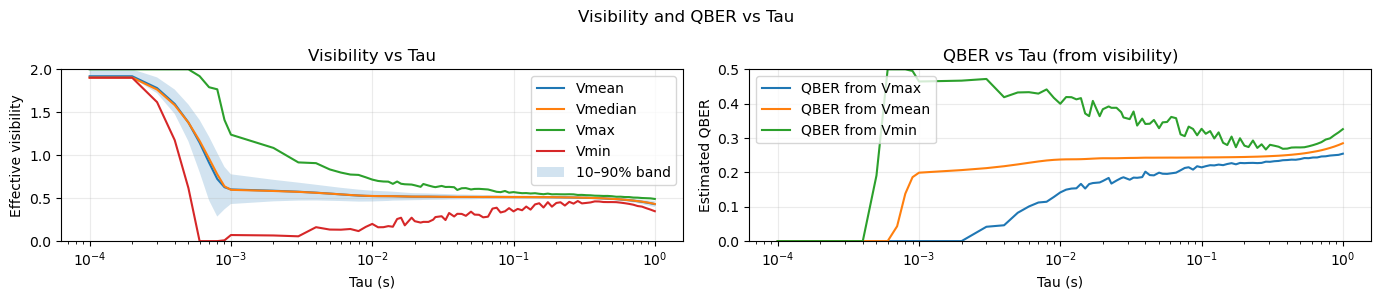

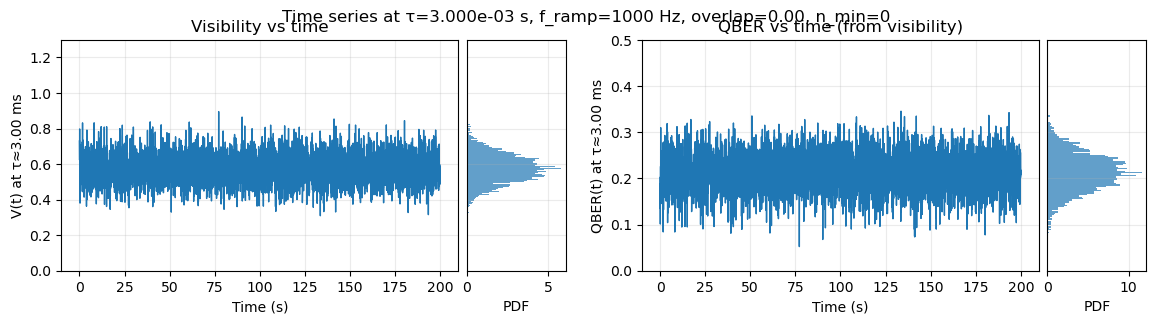

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 30, 'S': 30, 'tau': 0.003, 'step': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'mean_counts_per_window_used': 97.48043980439805}
V median: 0.5736057093427557
V mean:   0.5751393094269213
V 10–90%: 0.47207549483069844 … 0.6807726701923391


In [64]:
NL_1000_nm=Vis.AnalyseMeasurement_New(NL,4,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [117]:
for i in range(len(NLF)):
    print(i,NLF[i]['name'])

0 NightFast_2_1MhzGate_145uWperArm_Rmp1000Hz_voaramp
1 NightFast_2_1MhzGate_145uWperArm_Rmp100Hz_voaramp
2 NightFast_2_1MhzGate_145uWperArm_Rmp10Hz_voaramp
3 NightFast_2_1MhzGate_145uWperArm_Rmp1Hz_voaramp
4 NightFast_2_1MhzGate_145uWperArm_Rmp1000Hz_nomodulation
5 NightFast_2_1MhzGate_145uWperArm_Rmp100Hz_nomodulation
6 NightFast_2_1MhzGate_145uWperArm_Rmp10Hz_nomodulation
7 NightFast_2_1MhzGate_145uWperArm_Rmp1Hz_nomodulation
8 NightFast_2_1MhzGate_145uWperArm_Rmp1000Hz
9 NightFast_2_1MhzGate_145uWperArm_Rmp100Hz
10 NightFast_2_1MhzGate_145uWperArm_Rmp10Hz
11 NightFast_2_1MhzGate_145uWperArm_Rmp1Hz
12 NightFast_2_1MhzGate_158uWperArm_Rmp1Hz


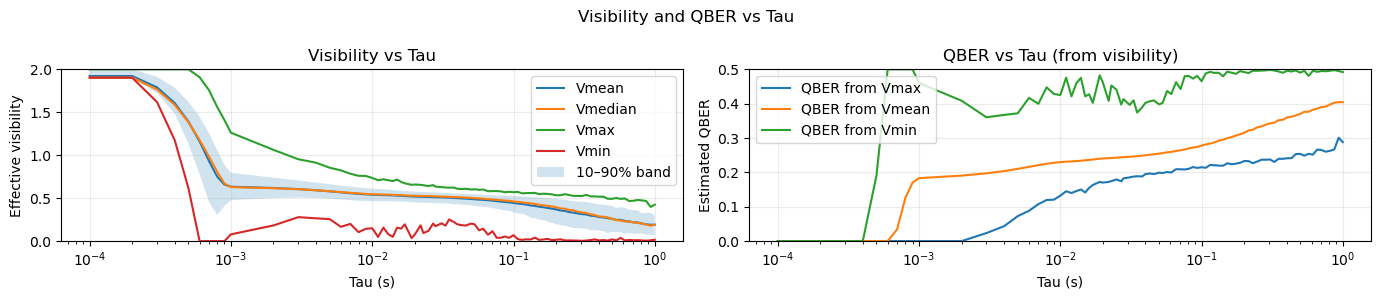

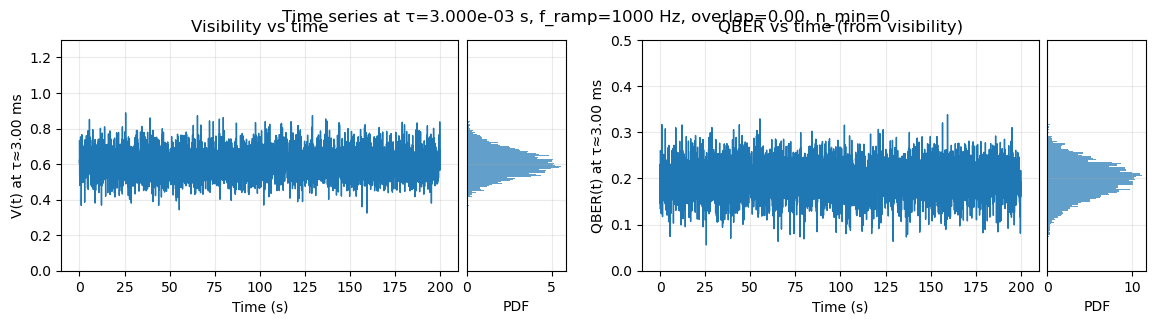

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 30, 'S': 30, 'tau': 0.003, 'step': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'mean_counts_per_window_used': 103.7420424204242}
V median: 0.604261530671781
V mean:   0.6056169444399623
V 10–90%: 0.50711536826923 … 0.7060733027383266


In [53]:
NLF_1000_em=Vis.AnalyseMeasurement_New(NLF,8,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

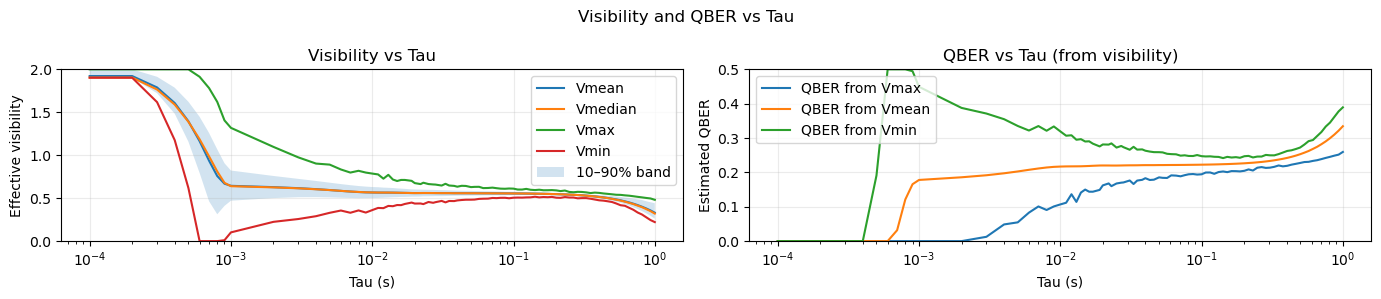

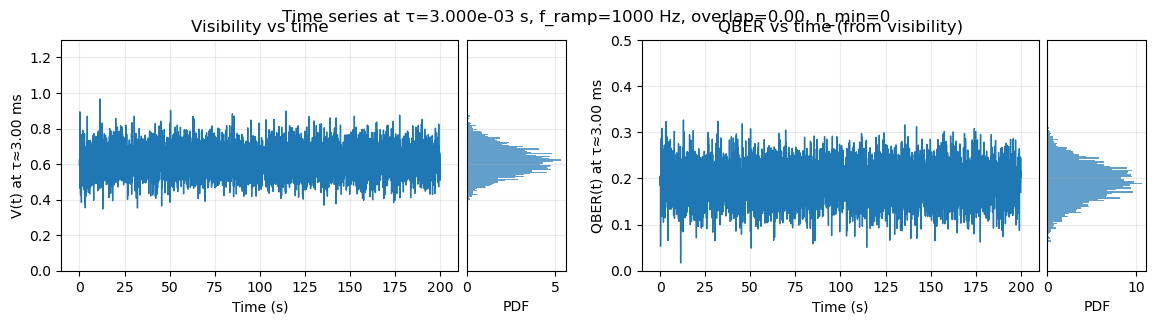

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 30, 'S': 30, 'tau': 0.003, 'step': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'mean_counts_per_window_used': 94.70206702067021}
V median: 0.6146969608221426
V mean:   0.6165787764722939
V 10–90%: 0.5111942394517043 … 0.7246164096756462


In [54]:
NLF_1000_nm=Vis.AnalyseMeasurement_New(NLF,4,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

In [123]:
for i in range(len(NLVF)):
    print(i,NLVF[i]['name'])

0 NightVeryFast_2_1MhzGate_147uWperArm_Rmp1000Hz_voaramp
1 NightVeryFast_2_1MhzGate_147uWperArm_Rmp100Hz_voaramp
2 NightVeryFast_2_1MhzGate_147uWperArm_Rmp10Hz_voaramp
3 NightVeryFast_2_1MhzGate_147uWperArm_Rmp1Hz_voaramp
4 NightVeryFast_2_1MhzGate_147uWperArm_Rmp1000Hz_nomodulation
5 NightVeryFast_2_1MhzGate_147uWperArm_Rmp100Hz_nomodulation
6 NightVeryFast_2_1MhzGate_147uWperArm_Rmp10Hz_nomodulation
7 NightVeryFast_2_1MhzGate_147uWperArm_Rmp1Hz_nomodulation
8 NightVeryFast_2_1MhzGate_147uWperArm_Rmp1000Hz
9 NightVeryFast_2_1MhzGate_147uWperArm_Rmp100Hz
10 NightVeryFast_2_1MhzGate_147uWperArm_Rmp10Hz
11 NightVeryFast_2_1MhzGate_147uWperArm_Rmp1Hz
12 NightVeryFast_2_1MhzGate_145uWperArm_Rmp1Hz


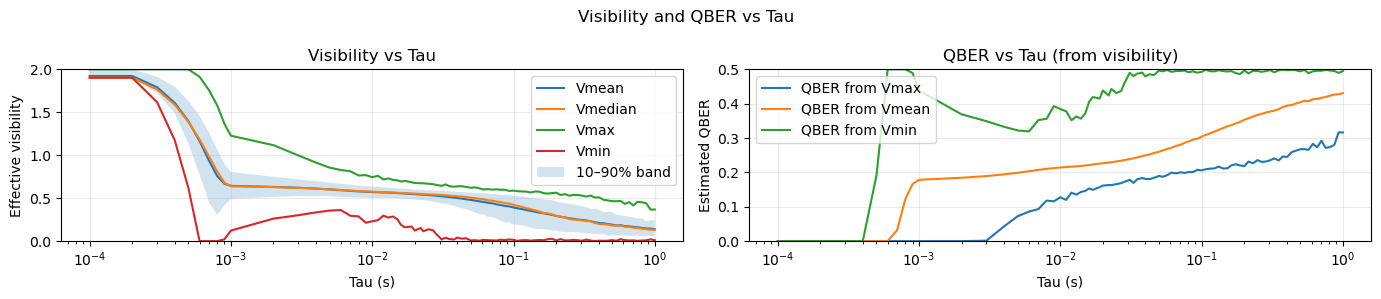

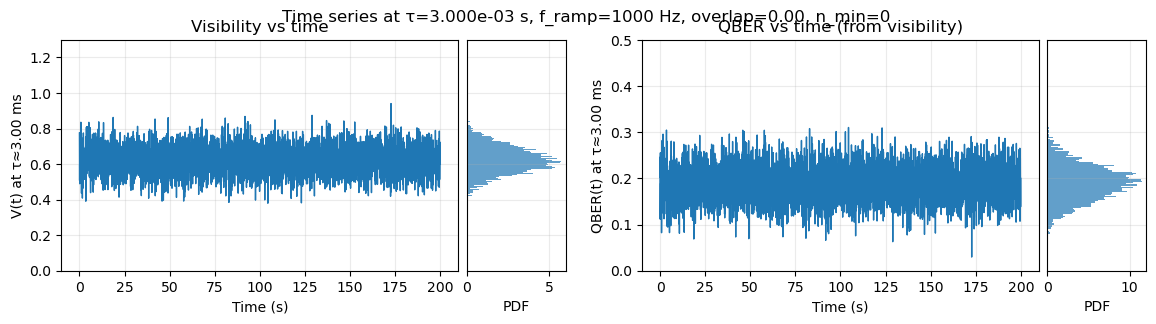

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 30, 'S': 30, 'tau': 0.003, 'step': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'mean_counts_per_window_used': 102.6830468304683}
V median: 0.6197015858495931
V mean:   0.6213163841356211
V 10–90%: 0.5247264002413803 … 0.719837145544969


In [55]:
NLVF_1000_em=Vis.AnalyseMeasurement_New(NLVF,8,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

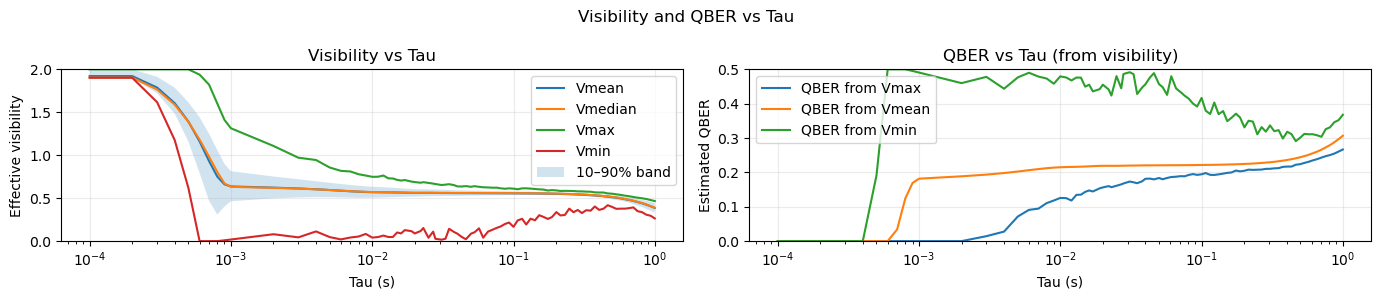

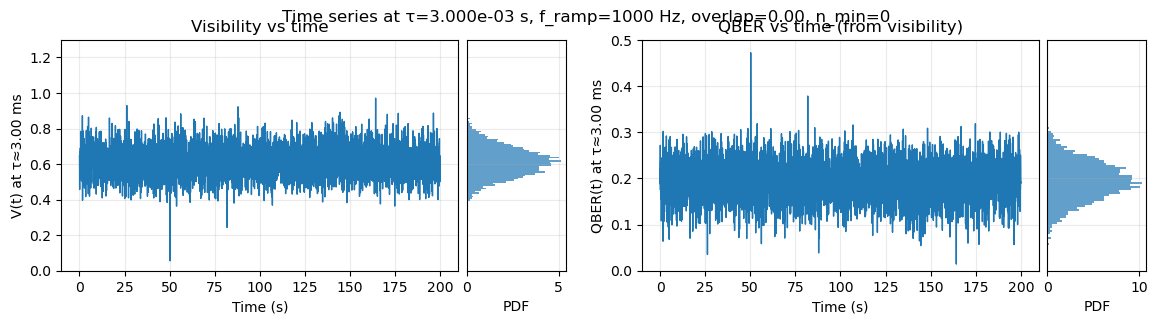

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 30, 'S': 30, 'tau': 0.003, 'step': 0.003, 'n_windows_total': 66666, 'n_windows_used': 66666, 'mean_counts_per_window_used': 94.84384843848439}
V median: 0.6116162369598834
V mean:   0.6129229910994335
V 10–90%: 0.5085801167492063 … 0.7201256089510892


In [56]:
NLVF_1000_nm=Vis.AnalyseMeasurement_New(NLVF,4,100,1000,1e-4,1,0.003,10,overlap=0,hist_bins=100)

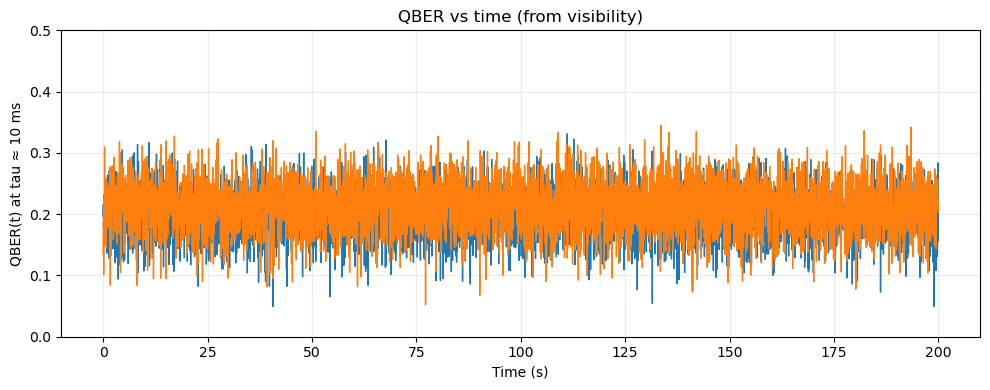

In [67]:
plt.figure(figsize=(10, 4))
plt.plot(NL_1000_em[0][2][0], NL_1000_em[0][2][1], linewidth=1)
plt.plot(NL_1000_nm[0][2][0], NL_1000_nm[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 10 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

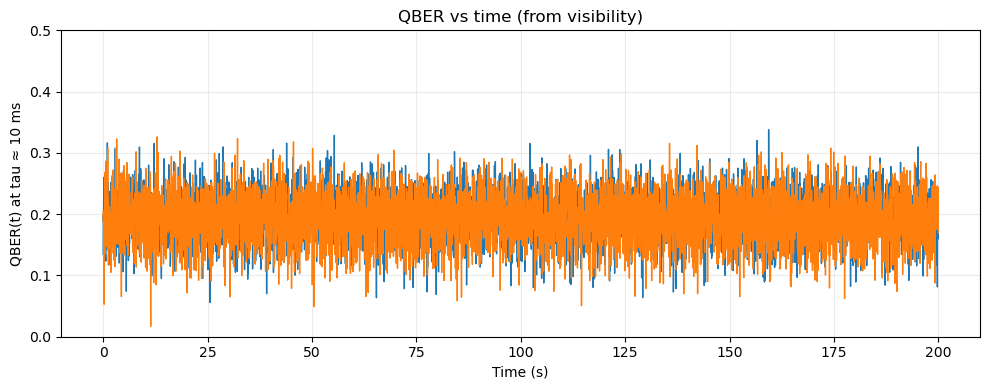

In [69]:
plt.figure(figsize=(10, 4))
plt.plot(NLF_1000_em[0][2][0], NLF_1000_em[0][2][1], linewidth=1)
plt.plot(NLF_1000_nm[0][2][0], NLF_1000_nm[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 10 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

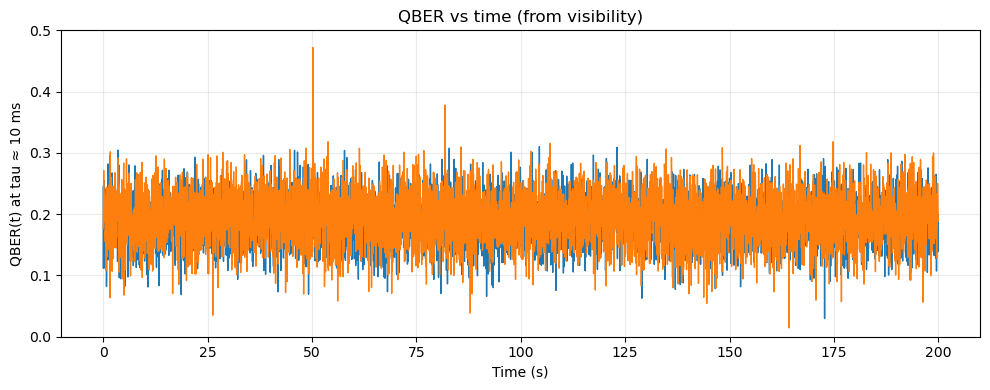

In [71]:
plt.figure(figsize=(10, 4))
plt.plot(NLVF_1000_em[0][2][0], NLVF_1000_em[0][2][1], linewidth=1)
plt.plot(NLVF_1000_nm[0][2][0], NLVF_1000_nm[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 10 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

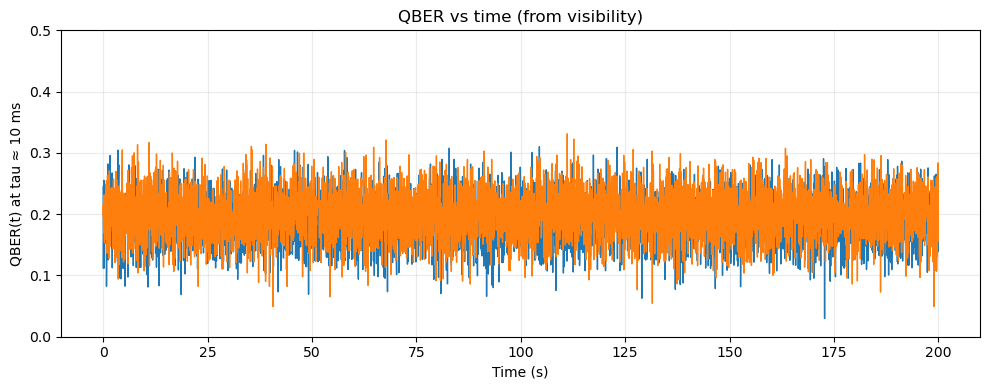

In [73]:
plt.figure(figsize=(10, 4))
plt.plot(NLVF_1000_em[0][2][0], NLVF_1000_em[0][2][1], linewidth=1)
plt.plot(NL_1000_em[0][2][0], NL_1000_em[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 10 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

In [75]:
np.save('NNF_1000_em.npy',NNF_1000_em[0][2])
np.save('NNF_1000_nm.npy',NNF_1000_nm[0][2])
np.save('NF_1000_em.npy',NF_1000_em[0][2])
np.save('NF_1000_nm.npy',NF_1000_nm[0][2])

In [77]:
np.save('DNF_1000_em.npy',DNF_1000_em[0][2])
np.save('DNF_1000_nm.npy',DNF_1000_nm[0][2])
np.save('DF_1000_em.npy',DF_1000_em[0][2])
np.save('DF_1000_nm.npy',DF_1000_nm[0][2])

In [79]:
np.save('MNF_1000_em.npy',MNF_1000_em[0][2])
np.save('MNF_1000_nm.npy',MNF_1000_nm[0][2])
np.save('MF_1000_em.npy',MF_1000_em[0][2])
np.save('MF_1000_nm.npy',MF_1000_nm[0][2])

In [81]:
np.save('NLVF_1000_em.npy',NLVF_1000_em[0][2])
np.save('NLVF_1000_nm.npy',NLVF_1000_nm[0][2])
np.save('NLF_1000_em.npy',NLF_1000_em[0][2])
np.save('NLF_1000_nm.npy',NLF_1000_nm[0][2])
np.save('NL_1000_em.npy',NL_1000_em[0][2])
np.save('NL_1000_nm.npy',NL_1000_nm[0][2])